In [21]:
import random
import math
import statistics
import matplotlib.pyplot as plt
import numpy as np

def info_market_maker(Information_fractions,seed,volatility=.2,trade_steps=1000,information_steps=100,customer_uncertainty=.8,spread = .2, informed_trade_probability=.65):
    rng = random.Random(seed)
    InformationProfit = []
    AvgTrades = []
    InformationLossRates = []
    PnlStdevs = []
    for informed_fraction in Information_fractions:
        total_profit = 0.0
        total_trades = 0
        losses = 0
        run_pnls = []
        for i in range(information_steps):
            fair_price = 100.0
            inventory = 0
            cash = 0.0
            max_inventory = 10
            order_flow_bias = .4
            arrival_sensitivity = .7
            trades = 0
            pnl = 0
            transaction_cost = .02
            for t in range(trade_steps):
                price_change = rng.gauss(0, volatility)

                bid = fair_price - spread / 2
                ask = fair_price + spread / 2

                arrival_prob = math.exp(-arrival_sensitivity * spread)
                if rng.random() < arrival_prob:
                    if rng.random() < informed_fraction:
                        if price_change > 0:
                            if rng.random() < informed_trade_probability:
                                buy_probability = (.5 + order_flow_bias)
                            else:
                                buy_probability = (.5 - order_flow_bias)
                        elif price_change <0:
                            if rng.random() < informed_trade_probability:
                                buy_probability = (.5 - order_flow_bias)
                            else:
                                buy_probability = (.5 + order_flow_bias)
                        else:
                            buy_probability = .5
                        if rng.random() < buy_probability and inventory > -max_inventory:
                            inventory -= 1
                            cash += ask - transaction_cost
                            trades += 1
                        elif rng.random() >= buy_probability and inventory < max_inventory:
                            inventory += 1
                            cash -= bid + transaction_cost
                            trades += 1
                    else:
                        customer_min_surplus = .05
                        customer_value = fair_price + rng.gauss(0, customer_uncertainty)
                        buy_surplus = customer_value - ask
                        sell_surplus = bid - customer_value
                        if buy_surplus > customer_min_surplus and buy_surplus >= sell_surplus and inventory > -max_inventory:
                            inventory -= 1
                            cash += ask - transaction_cost
                            trades += 1
                        elif sell_surplus > customer_min_surplus and sell_surplus > buy_surplus and inventory < max_inventory:
                            inventory += 1
                            cash -= bid + transaction_cost
                            trades += 1
                fair_price += price_change
            pnl += cash + inventory * fair_price
            run_pnls.append(pnl)
            total_profit += pnl

            if pnl < 0:
                losses += 1
            
            total_trades += trades
        average_trades = total_trades / information_steps
        loss_rate = losses / information_steps
        InformationLossRates.append(loss_rate)
        InformationProfit.append(total_profit / information_steps)
        AvgTrades.append(average_trades)
        PnlStdevs.append(statistics.stdev(run_pnls))
    return InformationProfit, AvgTrades, InformationLossRates, PnlStdevs

def improved_market_maker(Spreads,seed,volatility=.2,trade_steps=1000,spread_steps=100,customer_uncertainty=.8,informed_fraction=.1,informed_trade_probability=.65):
    rng = random.Random(seed)
    SpreadsProfit = []
    AvgTrades = []
    SpreadsLossRate = []
    PnlStdevs = []
    for spread in Spreads: 
        total_profit = 0.0
        total_trades = 0
        losses = 0
        run_pnls = []
        for i in range(spread_steps):
            fair_price = 100.0
            inventory = 0
            cash = 0.0
            max_inventory = 10
            order_flow_bias = .4
            arrival_sensitivity = .7
            trades = 0
            pnl = 0
            transaction_cost = .02
            for t in range(trade_steps):
                price_change = rng.gauss(0, volatility)

                bid = fair_price - spread / 2
                ask = fair_price + spread / 2

                arrival_prob = math.exp(-arrival_sensitivity * spread)
                if rng.random() < arrival_prob:
                    if rng.random() < informed_fraction:
                        if price_change > 0:
                            if rng.random() < informed_trade_probability:
                                buy_probability = (.5 + order_flow_bias)
                            else:
                                buy_probability = (.5 - order_flow_bias)
                        elif price_change <0:
                            if rng.random() < informed_trade_probability:
                                buy_probability = (.5 - order_flow_bias)
                            else:
                                buy_probability = (.5 + order_flow_bias)
                        else:
                            buy_probability = .5
                        if rng.random() < buy_probability and inventory > -max_inventory:
                            inventory -= 1
                            cash += ask - transaction_cost
                            trades += 1
                        elif rng.random() >= buy_probability and inventory < max_inventory:
                            inventory += 1
                            cash -= bid + transaction_cost
                            trades += 1
                    else:
                        customer_min_surplus = .05
                        customer_value = fair_price + rng.gauss(0, customer_uncertainty)
                        buy_surplus = customer_value - ask
                        sell_surplus = bid - customer_value
                        if buy_surplus > customer_min_surplus and buy_surplus >= sell_surplus and inventory > -max_inventory:
                            inventory -= 1
                            cash += ask - transaction_cost
                            trades += 1
                        elif sell_surplus > customer_min_surplus and sell_surplus > buy_surplus and inventory < max_inventory:
                            inventory += 1
                            cash -= bid + transaction_cost
                            trades += 1
                fair_price += price_change
            pnl += cash + inventory * fair_price
            run_pnls.append(pnl)
            total_profit += pnl

            if pnl < 0:
                losses += 1
            
            total_trades += trades
        average_trades = total_trades / spread_steps
        loss_rate = losses / spread_steps
        SpreadsLossRate.append(loss_rate)
        SpreadsProfit.append(total_profit / spread_steps)
        AvgTrades.append(average_trades)
        PnlStdevs.append(statistics.stdev(run_pnls))
    return SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs

def OptimalSpread(vol,seed = 42, customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65,spreads = [i/50 for i in range(1,125,1)]):
    SpreadsProfit, AvgTrades, SpreadsLossRate, PnlStdevs = improved_market_maker(spreads, seed=42, volatility=vol,customer_uncertainty=.8,informed_fraction=.5,informed_trade_probability=.65)
    coefficients_cubic = np.polyfit(spreads, SpreadsProfit, 3)
    a_cubic, b_cubic, c_cubic, d_cubic = coefficients_cubic
    spread_fit_cubic = np.linspace(min(spreads), max(spreads), 100)
    profit_fit_cubic = a_cubic * spread_fit_cubic**3 + b_cubic * spread_fit_cubic**2 + c_cubic * spread_fit_cubic + d_cubic
    optimal_spread = spread_fit_cubic[np.argmax(profit_fit_cubic)]
    return optimal_spread

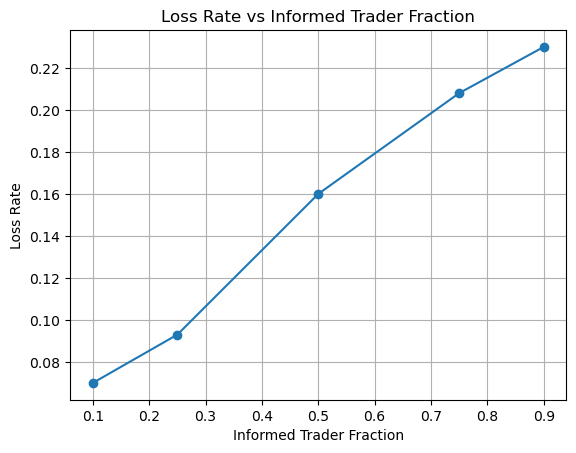

In [4]:
#From the research file, it is clear that the percentage of informed traders has some weird effect on the loss percentage, let's investigate further
#We will increase the number of steps per info fraction to 1000 to see a more consistent loss rate
Information_fractions = [.1,.25,.5,.75,.9]
information_steps = 1000
InfosProfit, AvgTrades, InfosLossRates, PnlStdevs = info_market_maker(Information_fractions,seed=42,information_steps=information_steps)
plt.plot(Information_fractions, InfosLossRates, marker='o')
plt.title('Loss Rate vs Informed Trader Fraction')
plt.xlabel('Informed Trader Fraction')
plt.ylabel('Loss Rate')
plt.grid()
plt.show()

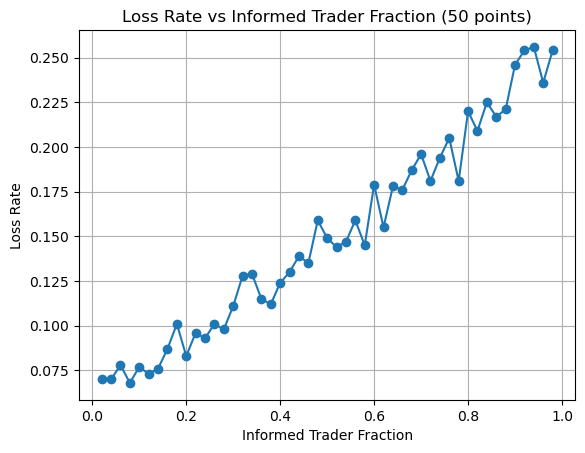

In [7]:
#Wow, very linear relationship, let's see how it looks with more points

Information_fractions = [i/50 for i in range(1, 50)]
information_steps = 1000
InfosProfit, AvgTrades, InfosLossRates, PnlStdevs = info_market_maker(Information_fractions,seed=42,information_steps=information_steps)
plt.plot(Information_fractions, InfosLossRates, marker='o')
plt.title('Loss Rate vs Informed Trader Fraction (50 points)')
plt.xlabel('Informed Trader Fraction')
plt.ylabel('Loss Rate')
plt.grid()
plt.show()

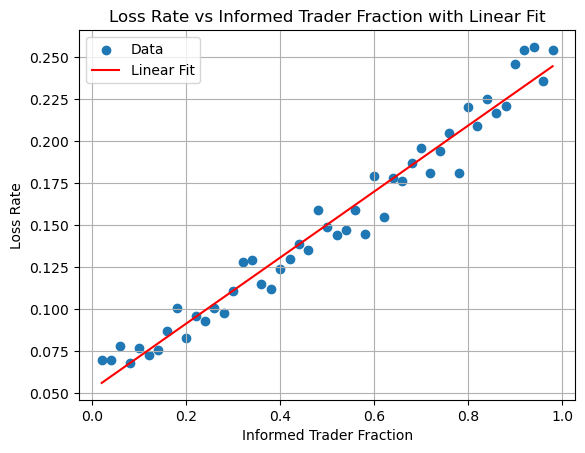

In [8]:
#Not as liinear as I thought, but still a clear trend, lets try a linear regression to see if we can get a good fit

Information_fractions = [i/50 for i in range(1, 50)]
information_steps = 1000
InfosProfit, AvgTrades, InfosLossRates, PnlStdevs = info_market_maker(Information_fractions,seed=42,information_steps=information_steps)
slope, intercept = np.polyfit(Information_fractions, InfosLossRates, 1)
plt.scatter(Information_fractions, InfosLossRates, marker='o', label='Data')
plt.plot(Information_fractions, [slope * x + intercept for x in Information_fractions], color='red', label='Linear Fit')
plt.title('Loss Rate vs Informed Trader Fraction with Linear Fit')
plt.xlabel('Informed Trader Fraction')
plt.ylabel('Loss Rate')
plt.legend()
plt.grid()
plt.show()

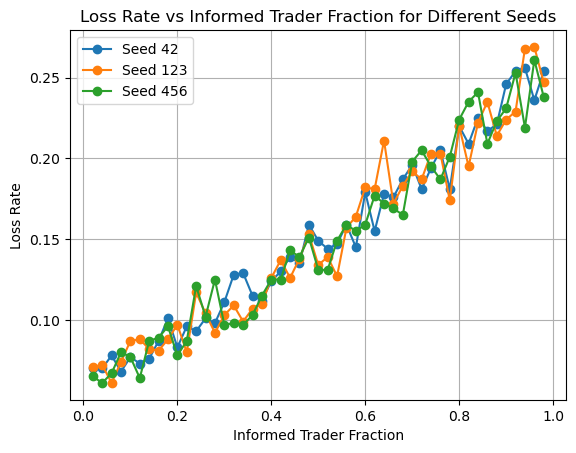

In [9]:
#Does this change from seed to seed? Let's try a few different seeds and see if the relationship holds
seeds = [42, 123, 456]
for i in seeds:
    Information_fractions = [i/50 for i in range(1, 50)]
    information_steps = 1000
    InfosProfit, AvgTrades, InfosLossRates, PnlStdevs = info_market_maker(Information_fractions,seed=i,information_steps=information_steps)
    plt.plot(Information_fractions, InfosLossRates, marker='o', label=f'Seed {i}')
plt.title('Loss Rate vs Informed Trader Fraction for Different Seeds')
plt.xlabel('Informed Trader Fraction')
plt.ylabel('Loss Rate')
plt.legend()
plt.grid()
plt.show()

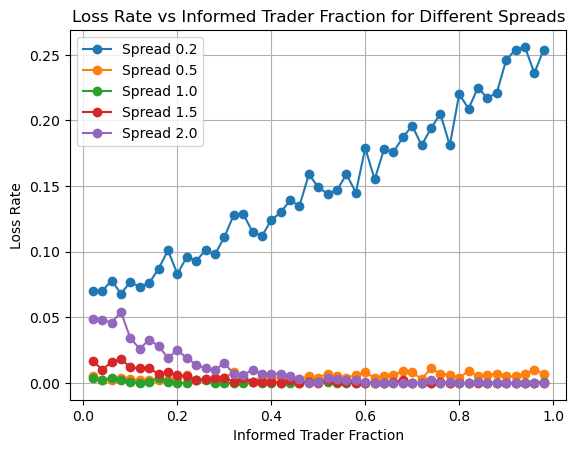

In [10]:
#So it seems it is rather consistent across seeds, but how does it change with different spread values?
spreads = [.2,.5,1.0,1.5,2.0]
for i in spreads:
    Information_fractions = [i/50 for i in range(1, 50)]
    information_steps = 1000
    InfosProfit, AvgTrades, InfosLossRates, PnlStdevs = info_market_maker(Information_fractions,seed=42,information_steps=information_steps,spread=i)
    plt.plot(Information_fractions, InfosLossRates, marker='o', label=f'Spread {i}')
plt.title('Loss Rate vs Informed Trader Fraction for Different Spreads')
plt.xlabel('Informed Trader Fraction')
plt.ylabel('Loss Rate')
plt.legend()
plt.grid()
plt.show()

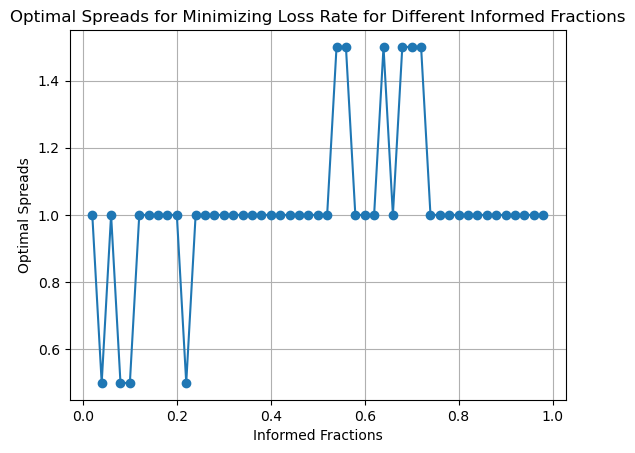

In [30]:
#Very interesting, whilst larget spreads lead to lower loss rates, but once a spread gets too big, uninformed customers are less willing to trade with such big margins.
#Now for each information level, we should find the best spread to minimize loss percentage

MinSpreads = [1 for i in range(1,50)]
MinSpreadsValues = [0 for i in range(1,50)]
for i in spreads:
    Information_fractions = [i/50 for i in range(1, 50)]
    information_steps = 1500
    InfosProfit, AvgTrades, InfosLossRates, PnlStdevs = info_market_maker(Information_fractions,seed=42,information_steps=information_steps,spread=i)
    for f in range(0,len(InfosLossRates)):
        if InfosLossRates[f] < MinSpreads[f]:
            MinSpreads[f] = InfosLossRates[f]
            MinSpreadsValues[f] = i

plt.plot(Information_fractions,MinSpreadsValues, marker='o')
plt.title("Optimal Spreads for Minimizing Loss Rate for Different Informed Fractions")
plt.xlabel("Informed Fractions")
plt.ylabel("Optimal Spreads")
plt.grid()
plt.show()

In [ ]:
#It seems the optimal spread for informed fraction of .5 hovers around the optimal spread found through volatility
x = OptimalSpread(.2)
InfosProfit, AvgTrades, InfosLossRates, PnlStdevs = info_market_maker([.5],seed=42,information_steps=2000,spread=x)
InfosProfit2, AvgTrades2, InfosLossRates2, PnlStdevs2 = info_market_maker([.5],seed=42,information_steps=2000,spread=1.5)
print(f"The loss rate for the optimal spread at vol=.2 is {InfosLossRates}, while the other spread's loss rate is {InfosLossRates2}")

The loss rate for the optimal spread at vol=.2 is [0.0005], while the other spread's loss rate is [0.0015]


In [36]:
InfosProfit, AvgTrades, InfosLossRates, PnlStdevs = info_market_maker([.5],seed=42,information_steps=2000,spread=.80)
print(f"{InfosLossRates}")

[0.0]
